In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, f1_score

np.random.seed(42)
n = 25920
sessions = np.repeat(np.arange(72), n // 72)

df = pd.DataFrame({
    'session_id': sessions,
    'distance_to_hazard': np.abs(np.random.normal(1.9, 0.8, n)),
    'velocity': np.abs(np.random.normal(0.31, 0.22, n)),
    'posture_class': np.random.choice([0, 1, 2, 3], n, p=[0.54, 0.31, 0.09, 0.06]),
    'time_to_contact': np.abs(np.random.normal(3.0, 1.5, n)),
    'hip_height_trend': np.random.normal(0.5, 0.15, n),
    'head_zone_alignment': np.random.normal(0.2, 0.1, n),
    'object_proximity': np.random.normal(0.3, 0.2, n),
    'joint_angles': np.random.normal(0.4, 0.2, n),
})

risk_probs = [0.55, 0.23, 0.12, 0.07, 0.03]
df['risk_level'] = np.random.choice([1, 2, 3, 4, 5], n, p=risk_probs)
df.to_csv('features.csv', index=False)
print(f'Generated {n} frames across 72 sessions')
df.head()

Generated 25920 frames across 72 sessions


,session_id,distance_to_hazard,velocity,posture_class,time_to_contact,hip_height_trend,head_zone_alignment,object_proximity,joint_angles,risk_level
0,0,2.297371,0.380740,1,2.835664,0.657295,0.325193,0.404304,0.160114,4
1,0,1.789389,0.603385,1,0.252869,0.554251,0.225216,0.563205,0.321378,2
2,0,2.418151,0.144583,2,6.720102,0.329829,0.295954,0.504620,0.718323,1
3,0,3.118424,0.811184,2,6.604074,0.559751,0.281447,0.515614,0.263725,1
4,0,1.712677,0.432511,3,3.667236,0.248000,0.252552,0.126031,0.201822,4


In [2]:
df.describe()

,session_id,distance_to_hazard,velocity,posture_class,time_to_contact,hip_height_trend,head_zone_alignment,object_proximity,joint_angles,risk_level
count,25920.000000,25920.000000,25920.000000,25920.000000,25920.000000,25920.000000,25920.000000,25920.000000,25920.000000,25920.000000
mean,35.500000,1.906243,0.325561,0.669637,3.027711,0.500106,0.200488,0.299892,0.399526,1.811998
std,20.783006,0.785895,0.195855,0.865465,1.454918,0.149733,0.100039,0.198972,0.200243,1.091000
min,0.000000,0.002056,0.000009,0.000000,0.000696,-0.099900,-0.179464,-0.436208,-0.474809,1.000000
25%,17.750000,1.363248,0.170134,0.000000,1.999207,0.400008,0.132233,0.165599,0.264234,1.000000
50%,35.500000,1.902389,0.311337,0.000000,2.997610,0.500809,0.199843,0.299102,0.399840,1.000000
75%,53.250000,2.438749,0.459251,1.000000,4.014533,0.599810,0.268753,0.432809,0.535274,2.000000
max,71.000000,5.483267,1.130123,3.000000,8.744673,1.130304,0.656211,1.095374,1.156438,5.000000


/tmp/ipykernel_16/3300367741.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='risk_level', data=df, palette='viridis')


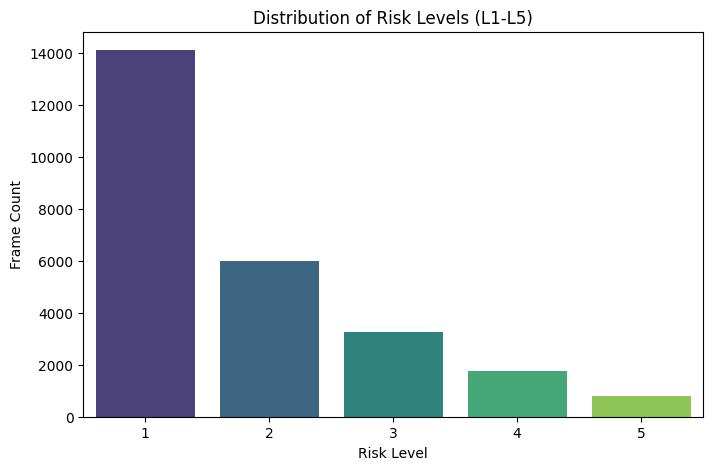

In [3]:
plt.figure(figsize=(8, 5))
sns.countplot(x='risk_level', data=df, palette='viridis')
plt.title('Distribution of Risk Levels (L1-L5)')
plt.xlabel('Risk Level')
plt.ylabel('Frame Count')
plt.show()

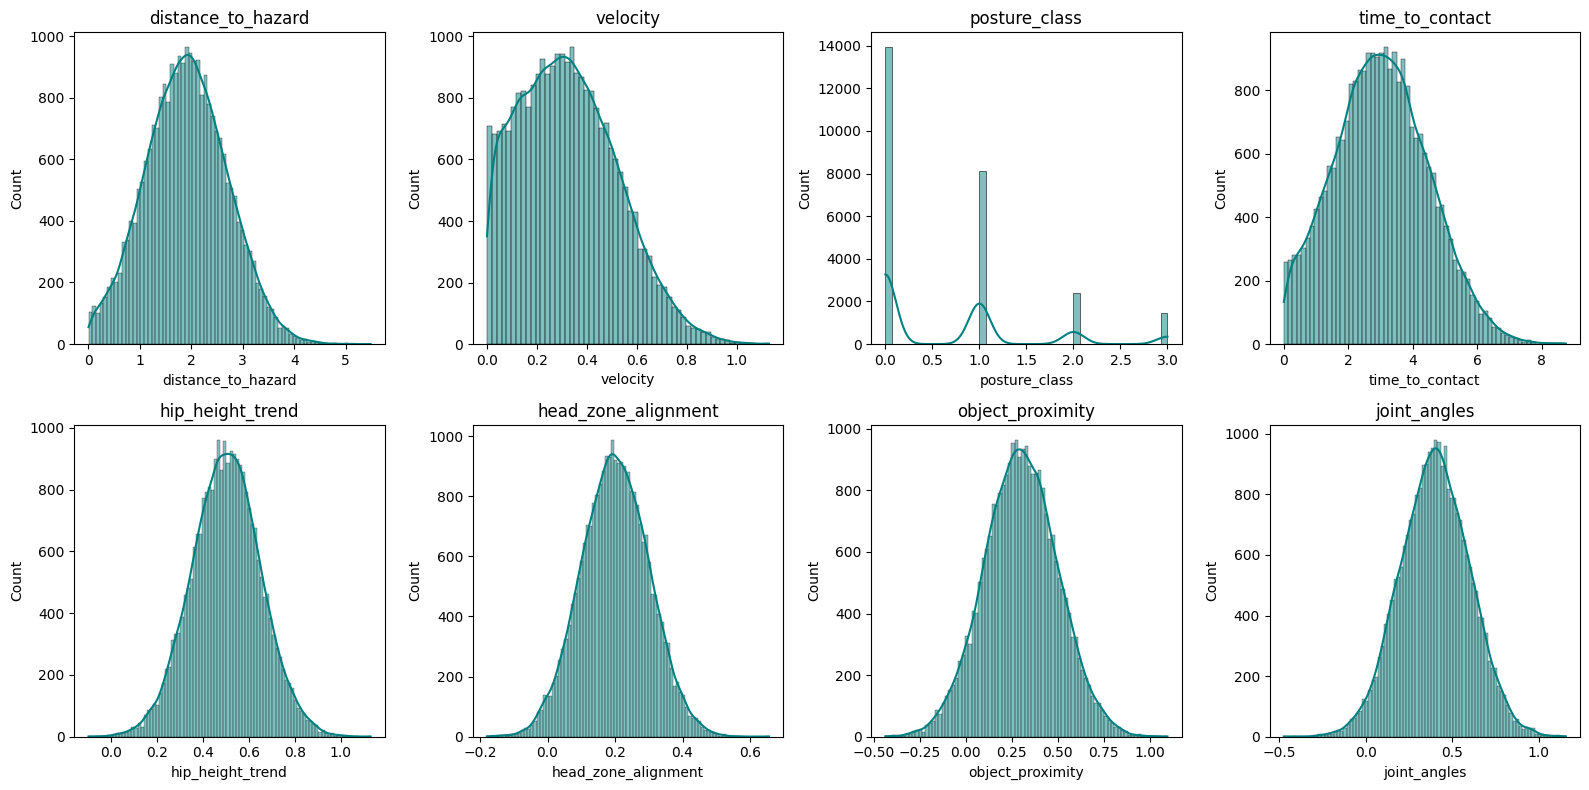

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
features = ['distance_to_hazard', 'velocity', 'posture_class',
            'time_to_contact', 'hip_height_trend', 'head_zone_alignment',
            'object_proximity', 'joint_angles']
for ax, feat in zip(axes.flatten(), features):
    sns.histplot(df[feat], ax=ax, kde=True, color='teal')
    ax.set_title(feat)
plt.tight_layout()
plt.show()

In [5]:
X = df.drop(columns=['risk_level', 'session_id']).values
y = df['risk_level'].values - 1
groups = df['session_id'].values

unique_sessions = np.unique(groups)
train_sessions, val_sessions = train_test_split(unique_sessions, test_size=0.3, random_state=42)
train_mask = np.isin(groups, train_sessions)
val_mask = np.isin(groups, val_sessions)

print(f'Train sessions: {len(train_sessions)}')
print(f'Validation sessions: {len(val_sessions)}')

Train sessions: 50
Validation sessions: 22


In [6]:
params = {
    'objective': 'multiclass', 'num_class': 5,
    'num_leaves': 31, 'max_depth': 6, 'learning_rate': 0.05,
    'n_estimators': 400, 'min_child_samples': 20,
    'feature_fraction': 0.9, 'bagging_fraction': 0.8,
    'class_weight': 'balanced', 'verbose': -1
}
model = lgb.LGBMClassifier(**params)
model.fit(X[train_mask], y[train_mask],
          eval_set=[(X[val_mask], y[val_mask])],
          callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)])

Training until validation scores don't improve for 50 rounds
[50]	valid_0's multi_logloss: 1.5884
[100]	valid_0's multi_logloss: 1.57296
[150]	valid_0's multi_logloss: 1.55904
[200]	valid_0's multi_logloss: 1.54541
[250]	valid_0's multi_logloss: 1.53104
[300]	valid_0's multi_logloss: 1.5187
[350]	valid_0's multi_logloss: 1.50757
[400]	valid_0's multi_logloss: 1.49848
Did not meet early stopping. Best iteration is:
[400]	valid_0's multi_logloss: 1.49848


LGBMClassifier(bagging_fraction=0.8, class_weight='balanced',
               feature_fraction=0.9, learning_rate=0.05, max_depth=6,
               n_estimators=400, num_class=5, objective='multiclass',
               verbose=-1)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


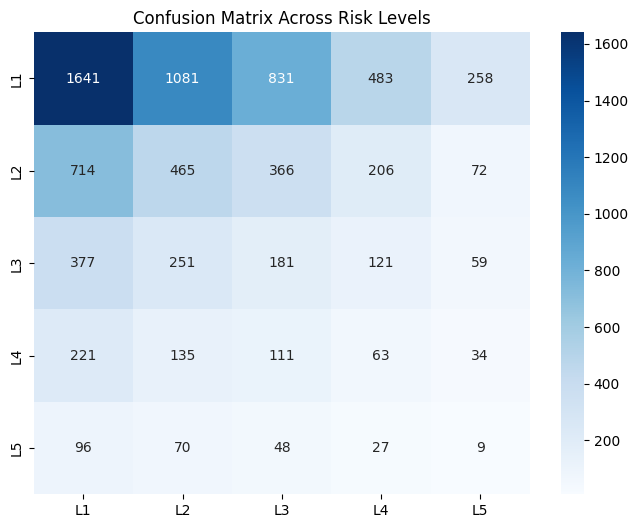

In [7]:
y_pred = model.predict(X[val_mask])
cm = confusion_matrix(y[val_mask], y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['L1','L2','L3','L4','L5'],
            yticklabels=['L1','L2','L3','L4','L5'])
plt.title('Confusion Matrix Across Risk Levels')
plt.show()

/tmp/ipykernel_16/3175676382.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importance, y=feature_names, palette='viridis')


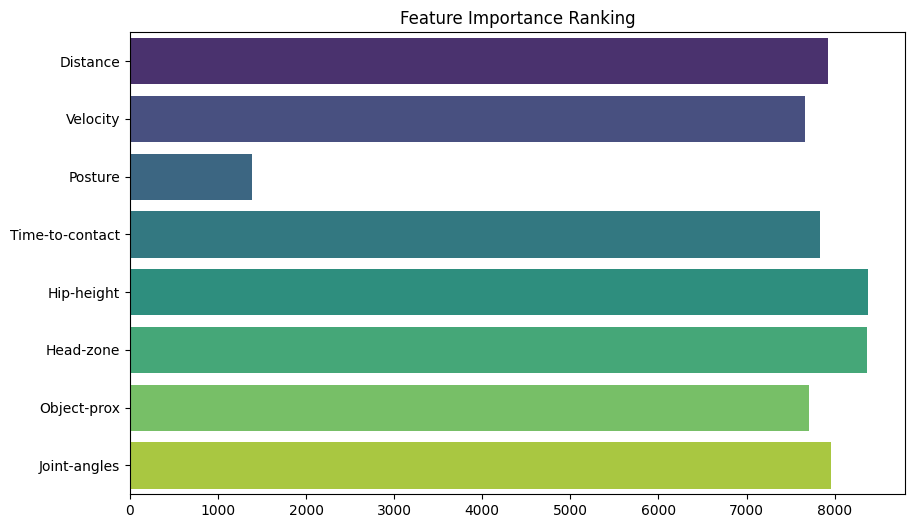

In [8]:
importance = model.feature_importances_
feature_names = ['Distance','Velocity','Posture','Time-to-contact',
                 'Hip-height','Head-zone','Object-prox','Joint-angles']
plt.figure(figsize=(10, 6))
sns.barplot(x=importance, y=feature_names, palette='viridis')
plt.title('Feature Importance Ranking')
plt.show()

In [9]:
results = []
for leaves in [16, 31, 63, 127]:
    for lr in [0.05, 0.10]:
        m = lgb.LGBMClassifier(objective='multiclass', num_class=5,
                               num_leaves=leaves, learning_rate=lr,
                               n_estimators=400, class_weight='balanced', verbose=-1)
        m.fit(X[train_mask], y[train_mask])
        yp = m.predict(X[val_mask])
        results.append({'leaves': leaves, 'lr': lr, 'f1': f1_score(y[val_mask], yp, average='weighted')})
sweep_df = pd.DataFrame(results)
print(sweep_df)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

   leaves    lr        f1
0      16  0.05  0.298340
1      16  0.10  0.325353
2      31  0.05  0.342841
3      31  0.10  0.375264
4      63  0.05  0.374742
5      63  0.10  0.392097
6     127  0.05  0.396127
7     127  0.10  0.395475


In [10]:
print(classification_report(y[val_mask], y_pred,
                            target_names=['L1','L2','L3','L4','L5'], digits=3))

              precision    recall  f1-score   support

          L1      0.538     0.382     0.447      4294
          L2      0.232     0.255     0.243      1823
          L3      0.118     0.183     0.143       989
          L4      0.070     0.112     0.086       564
          L5      0.021     0.036     0.026       250

    accuracy                          0.298      7920
   macro avg      0.196     0.194     0.189      7920
weighted avg      0.366     0.298     0.323      7920

